In [2]:
from google.colab import files
uploaded=files.upload()

Saving Sales_Dataset (1).xlsx to Sales_Dataset (1).xlsx


In [3]:
import pandas as pd

filename = next(iter(uploaded))
df = pd.read_excel(filename)

print(df.head())
print("Dataset shape:", df.shape)
print("Columns:", df.columns.tolist())

   OrderID  OrderDate CustomerName       City        State Region   Category  \
0  ORD0001 2025-08-07   Customer 1  Hyderabad    Telangana  South  Furniture   
1  ORD0002 2025-07-29   Customer 2      Delhi        Delhi  North  Furniture   
2  ORD0003 2025-01-21   Customer 3       Pune  Maharashtra   West     Office   
3  ORD0004 2025-10-15   Customer 4     Mumbai  Maharashtra   West  Furniture   
4  ORD0005 2025-04-06   Customer 5       Pune  Maharashtra   West     Office   

  Product  Quantity  UnitPrice     Sales     Cost   Profit Salesperson  \
0   Chair         3      19.07     57.21    48.91     8.30        Neha   
1   Chair         9     201.71   1815.39  1574.28   241.11        Neha   
2     Pen        10    1047.45  10474.50  6882.41  3592.09       Karan   
3    Desk         7     567.42   3971.94  3027.94   944.00       Priya   
4  Marker         9     110.43    993.87   861.92   131.95       Priya   

  PaymentMode  
0         UPI  
1         UPI  
2         UPI  
3  NetBank

In [4]:
#Check missing values
print("Missing Values:")
print(df.isnull().sum())

# Check duplicate rows
print("Duplicate Rows:", df.duplicated().sum())

# Remove duplicate rows
df = df.drop_duplicates()

# Check final dataset
print("Final Dataset Shape:", df.shape)

Missing Values:
OrderID         0
OrderDate       0
CustomerName    0
City            0
State           0
Region          0
Category        0
Product         0
Quantity        0
UnitPrice       0
Sales           0
Cost            0
Profit          0
Salesperson     0
PaymentMode     0
dtype: int64
Duplicate Rows: 0
Final Dataset Shape: (1000, 15)


In [6]:
print(df.columns.tolist())

['OrderID', 'OrderDate', 'CustomerName', 'City', 'State', 'Region', 'Category', 'Product', 'Quantity', 'UnitPrice', 'Sales', 'Cost', 'Profit', 'Salesperson', 'PaymentMode']


In [9]:
print(df["Sales"].sum())

3263332.89


In [11]:
df.groupby("Product")["Sales"].sum().sort_values(ascending=False)

,Sales
Product,
Pen,417187.05
Notebook,409025.31
Desk,401952.17
Mouse,395000.69
Keyboard,380833.20
Marker,378932.30
Chair,329145.05
Laptop,321345.08
Table,229912.04


In [13]:
df.groupby("Category")["Profit"].sum().sort_values(ascending=False)

,Profit
Category,
Office,370250.70
Electronics,330800.11
Furniture,278966.19


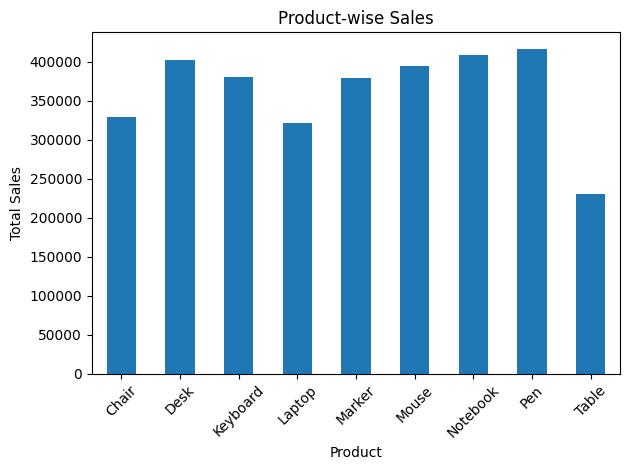

In [15]:
import matplotlib.pyplot as plt

df.groupby("Product")["Sales"].sum().plot(kind="bar")

plt.title("Product-wise Sales")
plt.xlabel("Product")
plt.ylabel("Total Sales")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [19]:
print("Total Sales:", df["Sales"].sum())
print("Total Profit:", df["Profit"].sum())

print("\nProduct-wise Sales:")
print(df.groupby("Product")["Sales"].sum().sort_values(ascending=False))

print("\nCity-wise Sales:")
print(df.groupby("City")["Sales"].sum().sort_values(ascending=False))

Total Sales: 3263332.89
Total Profit: 980017.0

Product-wise Sales:
Product
Pen         417187.05
Notebook    409025.31
Desk        401952.17
Mouse       395000.69
Keyboard    380833.20
Marker      378932.30
Chair       329145.05
Laptop      321345.08
Table       229912.04
Name: Sales, dtype: float64

City-wise Sales:
City
Pune         694601.65
Mumbai       677546.86
Bengaluru    658198.70
Delhi        626419.65
Hyderabad    606566.03
Name: Sales, dtype: float64


In [18]:
df.groupby("Region")["Sales"].sum().sort_values(ascending=False)

,Sales
Region,
West,1372148.51
South,1264764.73
North,626419.65
